In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [55]:
import os

print("Searching all of /kaggle/input for JSON files...\n")

found = []

for current, dirs, files in os.walk("/kaggle/input"):
    for filename in files:
        if filename.lower().endswith(".json"):
            path = os.path.join(current, filename)
            found.append(path)
            print(path)

print("\nTotal JSON files found:", len(found))

Searching all of /kaggle/input for JSON files...

/kaggle/input/datasets/jameelarham/frames-sampled/sampled_training_metadata (1).json
/kaggle/input/datasets/jameelarham/frames-sampled/sampled_testing_complete/sampled_testing_metadata.json
/kaggle/input/datasets/jameelarham/frames-sampled/sampled_validation_complete (1)/sampled_validation_metadata.json

Total JSON files found: 3


In [58]:
import json
import os

files = {
    "Testing": "/kaggle/working/sampled_testing_metadata.json",
    "Validation": "/kaggle/working/sampled_validation_metadata.json",
    "Training": "/kaggle/input/datasets/jameelarham/frames-sampled/sampled_training_metadata (1).json"
}

for split, path in files.items():
    print(f"\n{split}:")

    if not os.path.exists(path):
        print("Corrected copy not found at this path.")
        continue

    with open(path, "r") as f:
        data = json.load(f)

    unlabeled = [x for x in data if not x.get("class")]

    print("Total records:", len(data))
    print("Still unlabeled:", len(unlabeled))


Testing:
Total records: 200
Still unlabeled: 0

Validation:
Total records: 194
Still unlabeled: 0

Training:
Total records: 940
Still unlabeled: 0


In [61]:
import os
import json

metadata_files = {
    "train": "/kaggle/working/sampled_training_metadata.json",
    "validation": "/kaggle/working/sampled_validation_metadata.json",
    "test": "/kaggle/working/sampled_testing_metadata.json"
}

for split, path in metadata_files.items():
    if not os.path.exists(path):
        print(f"{split}: FILE NOT FOUND — {path}")
        continue

    with open(path, "r") as f:
        data = json.load(f)

    unlabeled = sum(
        1 for item in data
        if not item.get("class")
    )

    print(
        f"{split}: {len(data)} videos | "
        f"{unlabeled} unlabeled | "
        f"JSON found"
    )

train: 940 videos | 0 unlabeled | JSON found
validation: 194 videos | 0 unlabeled | JSON found
test: 200 videos | 0 unlabeled | JSON found


In [2]:
import tensorflow as tf
from tensorflow.keras.applications import ResNet50

print("GPU:", tf.config.list_physical_devices("GPU"))

cnn = ResNet50(
    weights="imagenet",
    include_top=False,
    pooling="avg",
    input_shape=(224, 224, 3)
)

cnn.trainable = False

print("ResNet50 loaded successfully!")
print("Output shape:", cnn.output_shape)

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
ResNet50 loaded successfully!
Output shape: (None, 2048)


In [3]:
import os

FRAME_DIRS = {
    "train": "/kaggle/input/datasets/jameelarham/frames-sampled/sampled_training_frames_backup",
    "validation": "/kaggle/input/datasets/jameelarham/frames-sampled/sampled_validation_complete (1)/sampled_validation_frames",
    "test": "/kaggle/input/datasets/jameelarham/frames-sampled/sampled_testing_complete/sampled_testing_frames"
}

for split, path in FRAME_DIRS.items():
    print(f"{split}: {'FOUND' if os.path.isdir(path) else 'NOT FOUND'}")

train: FOUND
validation: FOUND
test: FOUND


In [12]:
import os
import json
import cv2
import numpy as np
import tensorflow as tf

from tensorflow.keras.applications.resnet50 import preprocess_input

# Existing frame folders
FRAME_DIRS = {
    "train": "/kaggle/input/datasets/jameelarham/frames-sampled/sampled_training_frames_backup",
    "validation": "/kaggle/input/datasets/jameelarham/frames-sampled/sampled_validation_complete (1)/sampled_validation_frames",
    "test": "/kaggle/input/datasets/jameelarham/frames-sampled/sampled_testing_complete/sampled_testing_frames"
}

# Metadata files in working directory
JSON_PATHS = {
    "train": "/kaggle/working/sampled_training_metadata.json",
    "validation": "/kaggle/working/sampled_validation_metadata.json",
    "test": "/kaggle/working/sampled_testing_metadata.json"
}

OUTPUT_DIR = "/kaggle/working/resnet50_features"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Load metadata
metadata = {}

for split, path in JSON_PATHS.items():
    with open(path, "r") as f:
        metadata[split] = json.load(f)

# Build one consistent class-to-number mapping
classes = sorted({
    str(item["class"])
    for records in metadata.values()
    for item in records
    if item.get("class")
})

class_to_index = {name: i for i, name in enumerate(classes)}

with open(os.path.join(OUTPUT_DIR, "class_mapping.json"), "w") as f:
    json.dump(class_to_index, f, indent=2)

print("Classes:", len(classes))
print("GPU:", tf.config.list_physical_devices("GPU"))

# Load pretrained CNN
cnn = tf.keras.applications.ResNet50(
    weights="imagenet",
    include_top=False,
    pooling="avg",
    input_shape=(224, 224, 3)
)
cnn.trainable = False

BATCH_SIZE = 64

def get_video_folder(item, root):
    # Try the video identifier and video name
    candidates = []

    for key in ("video_id", "video_name"):
        value = item.get(key)
        if value:
            candidates.append(os.path.join(root, str(value)))
            candidates.append(
                os.path.join(root, os.path.splitext(os.path.basename(str(value)))[0])
            )

    for folder in candidates:
        if os.path.isdir(folder):
            return folder

    raise FileNotFoundError(
        f"Could not find frame folder for: {item.get('video_name', item.get('video_id'))}"
    )

def extract_video_features(item, root):
    folder = get_video_folder(item, root)

    frame_paths = sorted(
        os.path.join(folder, name)
        for name in os.listdir(folder)
        if name.lower().endswith((".jpg", ".jpeg", ".png"))
    )

    if len(frame_paths) != 40:
        raise ValueError(
            f"Expected 40 frames, found {len(frame_paths)} in {folder}"
        )

    features = []

    for start in range(0, len(frame_paths), BATCH_SIZE):
        batch_paths = frame_paths[start:start + BATCH_SIZE]
        images = []

        for path in batch_paths:
            image = cv2.imread(path)

            if image is None:
                raise ValueError(f"Could not read frame: {path}")

            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            images.append(image)

        batch = np.asarray(images, dtype=np.float32)
        batch = preprocess_input(batch)

        batch_features = cnn(batch, training=False).numpy()
        features.append(batch_features)

    return np.concatenate(features, axis=0)

# Extract and save each split
for split in ("train", "validation", "test"):
    records = metadata[split]
    X = np.empty((len(records), 40, 2048), dtype=np.float32)
    y = np.empty(len(records), dtype=np.int32)

    print(f"\nStarting {split}: {len(records)} videos")

    for i, item in enumerate(records):
        label = item.get("class")

        if not label or str(label) not in class_to_index:
            raise ValueError(
                f"Missing or unknown class in {split}, record {i}: {label}"
            )

        X[i] = extract_video_features(item, FRAME_DIRS[split])
        y[i] = class_to_index[str(label)]

        if (i + 1) % 25 == 0 or i + 1 == len(records):
            print(f"{split}: {i + 1}/{len(records)} videos processed")

    np.save(os.path.join(OUTPUT_DIR, f"X_{split}.npy"), X)
    np.save(os.path.join(OUTPUT_DIR, f"y_{split}.npy"), y)

    print(f"Saved X_{split}: {X.shape}")
    print(f"Saved y_{split}: {y.shape}")

print("\nALL FEATURE EXTRACTION COMPLETED!")
print("Output directory:", OUTPUT_DIR)

Classes: 21
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]

Starting train: 940 videos
train: 25/940 videos processed
train: 50/940 videos processed
train: 75/940 videos processed
train: 100/940 videos processed
train: 125/940 videos processed
train: 150/940 videos processed
train: 175/940 videos processed
train: 200/940 videos processed
train: 225/940 videos processed
train: 250/940 videos processed
train: 275/940 videos processed
train: 300/940 videos processed
train: 325/940 videos processed
train: 350/940 videos processed
train: 375/940 videos processed
train: 400/940 videos processed
train: 425/940 videos processed
train: 450/940 videos processed
train: 475/940 videos processed
train: 500/940 videos processed
train: 525/940 videos processed
train: 550/940 videos processed
train: 575/940 videos processed
train: 600/940 videos processed
train: 625/940 videos processed
train: 650/940 videos pro

Training features: (940, 40, 2048)
Validation features: (194, 40, 2048)
Number of classes: 21
SVM training input: (940, 2048)
SVM validation input: (194, 2048)


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


SVM training completed!

Validation accuracy: 0.4433
Macro precision: 0.4599
Macro recall: 0.4173
Macro F1-score: 0.4296

Classification report:
                            precision    recall  f1-score   support

                     Abuse       0.67      0.57      0.62         7
                    Arrest       0.00      0.00      0.00         7
                     Arson       0.17      0.14      0.15         7
                   Assault       0.14      0.14      0.14         7
                  Burglary       0.33      0.20      0.25        10
                  Clapping       1.00      1.00      1.00        10
                 Explosion       0.22      0.29      0.25         7
                  Fighting       0.00      0.00      0.00         7
            Meet_and_Split       0.50      0.40      0.44        10
             Normal_Videos       0.31      0.25      0.28        20
             RoadAccidents       0.18      0.20      0.19        10
                   Robbery       0.50 

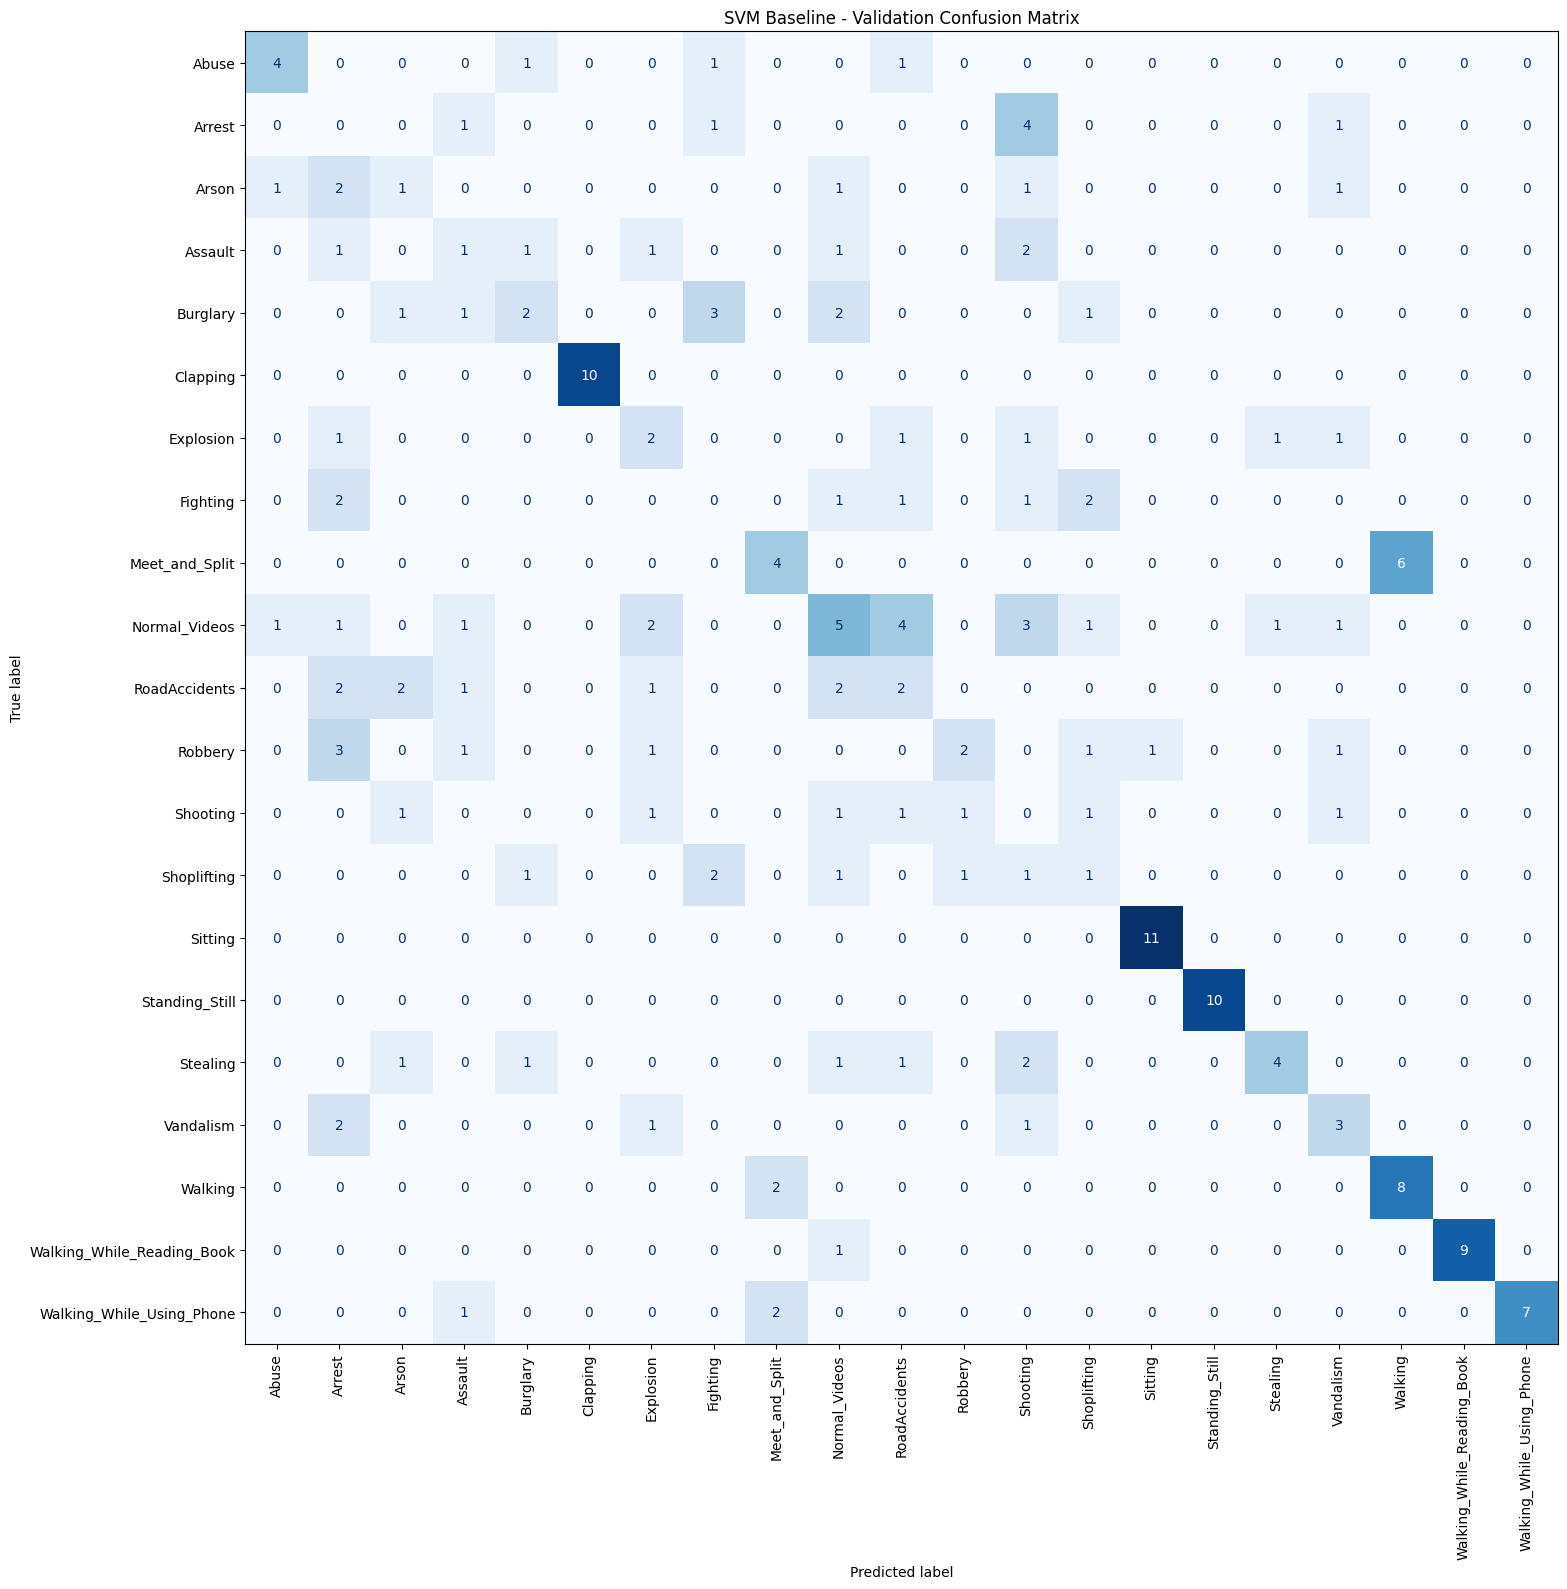


Saved model: /kaggle/working/resnet50_features/svm_baseline.joblib
Saved confusion matrix: /kaggle/working/resnet50_features/svm_validation_confusion_matrix.png
Saved metrics: /kaggle/working/resnet50_features/svm_validation_metrics.json


In [13]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score
)

# 1. Load saved CNN features
FEATURE_DIR = "/kaggle/working/resnet50_features"

required_files = [
    "X_train.npy", "y_train.npy",
    "X_validation.npy", "y_validation.npy",
    "class_mapping.json"
]

for filename in required_files:
    path = os.path.join(FEATURE_DIR, filename)
    if not os.path.isfile(path):
        raise FileNotFoundError(f"Missing required file: {path}")

X_train = np.load(os.path.join(FEATURE_DIR, "X_train.npy"))
y_train = np.load(os.path.join(FEATURE_DIR, "y_train.npy"))

X_val = np.load(os.path.join(FEATURE_DIR, "X_validation.npy"))
y_val = np.load(os.path.join(FEATURE_DIR, "y_validation.npy"))

with open(os.path.join(FEATURE_DIR, "class_mapping.json")) as f:
    class_to_index = json.load(f)

# Convert mapping into class names in numerical-label order
class_names = [
    name for name, index in
    sorted(class_to_index.items(), key=lambda pair: pair[1])
]

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Number of classes:", len(class_names))

# 2. Average the 40 frame features into one vector per video
# (videos, 40 frames, 2048 features) -> (videos, 2048 features)
X_train_svm = X_train.mean(axis=1)
X_val_svm = X_val.mean(axis=1)

print("SVM training input:", X_train_svm.shape)
print("SVM validation input:", X_val_svm.shape)

# 3. Train an SVM baseline
svm_model = make_pipeline(
    StandardScaler(),
    LinearSVC(class_weight="balanced", max_iter=10000, random_state=42)
)

svm_model.fit(X_train_svm, y_train)
print("SVM training completed!")

# 4. Predict validation classes
y_pred = svm_model.predict(X_val_svm)

# 5. Evaluation metrics
print(f"\nValidation accuracy: {accuracy_score(y_val, y_pred):.4f}")
print(f"Macro precision: {precision_score(y_val, y_pred, average='macro', zero_division=0):.4f}")
print(f"Macro recall: {recall_score(y_val, y_pred, average='macro', zero_division=0):.4f}")
print(f"Macro F1-score: {f1_score(y_val, y_pred, average='macro', zero_division=0):.4f}")

print("\nClassification report:")
print(classification_report(
    y_val,
    y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0
))

# 6. Confusion matrix
cm = confusion_matrix(
    y_val,
    y_pred,
    labels=np.arange(len(class_names))
)

fig, ax = plt.subplots(figsize=(16, 16))
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
display.plot(ax=ax, xticks_rotation=90, cmap="Blues", colorbar=False)
plt.title("SVM Baseline - Validation Confusion Matrix")
plt.tight_layout()

cm_path = os.path.join(FEATURE_DIR, "svm_validation_confusion_matrix.png")
plt.savefig(cm_path, dpi=200, bbox_inches="tight")
plt.show()

# 7. Save the trained model and metrics
joblib.dump(
    svm_model,
    os.path.join(FEATURE_DIR, "svm_baseline.joblib")
)

metrics = {
    "validation_accuracy": float(accuracy_score(y_val, y_pred)),
    "macro_precision": float(precision_score(y_val, y_pred, average="macro", zero_division=0)),
    "macro_recall": float(recall_score(y_val, y_pred, average="macro", zero_division=0)),
    "macro_f1": float(f1_score(y_val, y_pred, average="macro", zero_division=0))
}

with open(os.path.join(FEATURE_DIR, "svm_validation_metrics.json"), "w") as f:
    json.dump(metrics, f, indent=2)

print("\nSaved model:", os.path.join(FEATURE_DIR, "svm_baseline.joblib"))
print("Saved confusion matrix:", cm_path)
print("Saved metrics:", os.path.join(FEATURE_DIR, "svm_validation_metrics.json"))